# Confounder classification using gpt4
## Imports

In [8]:
import os
import sys
import yaml
from tqdm import tqdm
from PIL import Image

# Add the project root directory to sys.path
project_root = os.path.abspath("../..")  # Adjust this path if needed
sys.path.append(project_root)

from utils import get_n_confounded_m_non_confounded_images
from confounder_classification_gpt4 import run_instance_gpt4


## Datasets
### Load ISIC 2019 dataset

In [9]:
# Load the YAML file into a dictionary
dataset_yaml_file = "/workspace/home/data/datasets.yaml"
with open(dataset_yaml_file, "r") as file:
    datasets = yaml.safe_load(file)


# get dataset
dataset_key = "ISIC2019"
dataset = datasets[dataset_key]

## Setup images, prompt and outputs that lead to label True/1

The ```prompt```(TODO) and ```output_for_true``` can be set in the datasets.yaml file. The ```prompt``` is the question feeded to the model. The ```output_for_true``` are the answers of the model that we expect if the confounder is present and the label is set to true.

In [10]:
# get n confounded and m non-confounded images
images_path = dataset["raw_path"]
gt_csv_path = dataset["gt_label_path"]

imgs_confounded, imgs_non_confounded = get_n_confounded_m_non_confounded_images(images_path, gt_csv_path, n=5, m=5)
images = imgs_confounded + imgs_non_confounded


# set prompt
prompt = "This image is from a set of images from skin lesions. We want to identify whether there are confounding factors in the images of this dataset. We identified that colored patches (also called stickers) are confounding factors in this dataset. Is there such a colored patch in this image? Please reply with 'yes' or 'no'."


# Model outputs that are considered as True
output_for_true = dataset["output_for_true"]

## Run model on images, print output and visualize the image

  0%|          | 0/12 [00:00<?, ?it/s]

Image: ISIC_0000557.jpg, Output: Yes., Label: 1


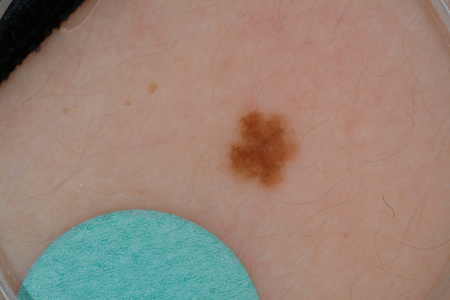

  8%|▊         | 1/12 [00:05<01:03,  5.74s/it]

Image: ISIC_0000558.jpg, Output: Yes, Label: 1


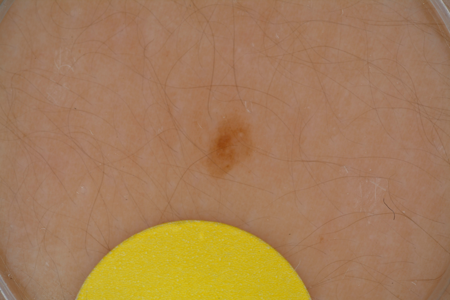

 17%|█▋        | 2/12 [00:09<00:47,  4.74s/it]

Image: ISIC_0000559.jpg, Output: Yes., Label: 1


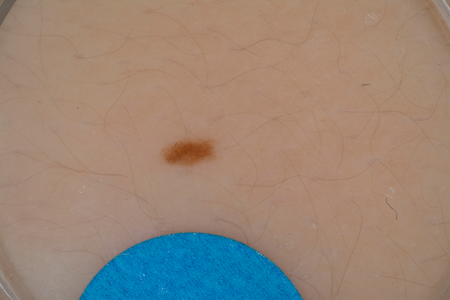

 25%|██▌       | 3/12 [00:15<00:47,  5.29s/it]

Image: ISIC_0000560.jpg, Output: Yes., Label: 1


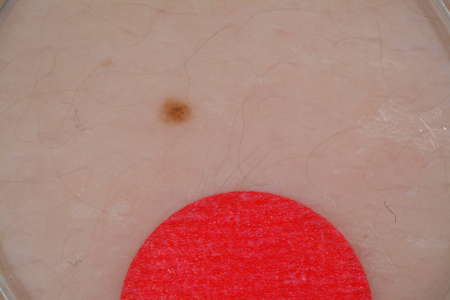

 33%|███▎      | 4/12 [00:20<00:39,  4.90s/it]

Image: ISIC_0000561.jpg, Output: Yes., Label: 1


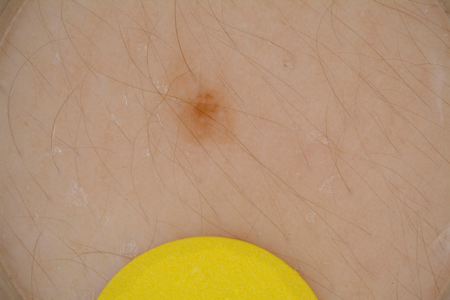

 42%|████▏     | 5/12 [00:25<00:35,  5.06s/it]

Image: ISIC_0000562.jpg, Output: Yes., Label: 1


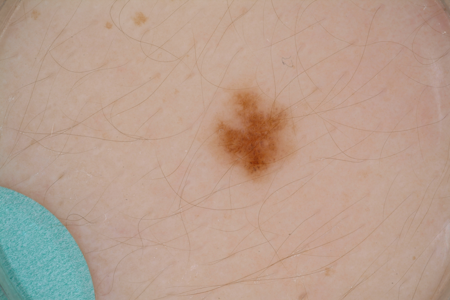

 50%|█████     | 6/12 [00:29<00:28,  4.70s/it]

Image: ISIC_0000000.jpg, Output: No., Label: 0


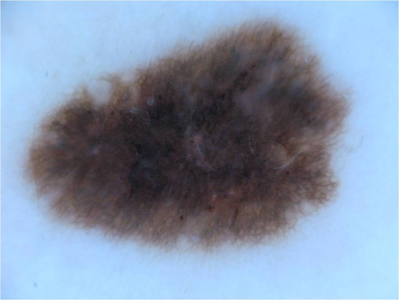

 58%|█████▊    | 7/12 [00:31<00:20,  4.02s/it]

Image: ISIC_0000001.jpg, Output: No., Label: 0


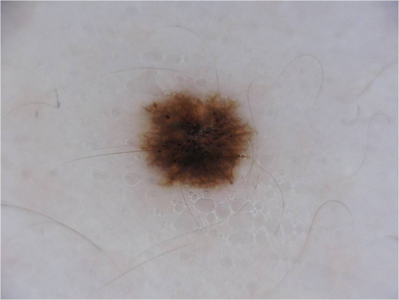

 67%|██████▋   | 8/12 [00:33<00:13,  3.26s/it]

Image: ISIC_0000002.jpg, Output: No., Label: 0


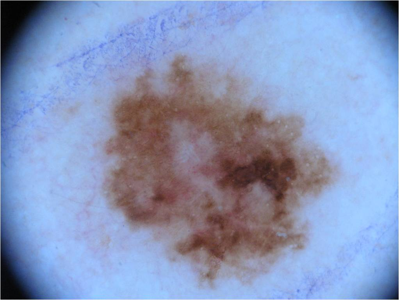

 75%|███████▌  | 9/12 [00:37<00:09,  3.30s/it]

Image: ISIC_0000003.jpg, Output: no, Label: 0


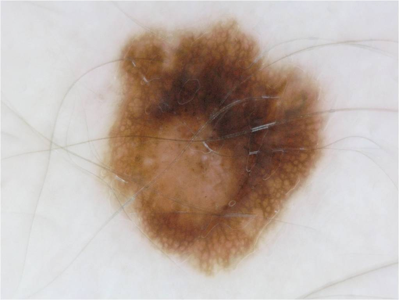

 83%|████████▎ | 10/12 [00:40<00:06,  3.30s/it]

Image: ISIC_0000004.jpg, Output: No., Label: 0


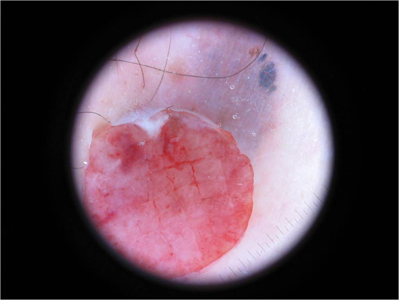

 92%|█████████▏| 11/12 [00:42<00:03,  3.02s/it]

Image: ISIC_0000005.jpg, Output: no, Label: 0


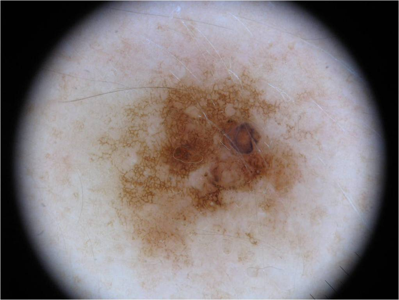

100%|██████████| 12/12 [00:44<00:00,  3.72s/it]


In [11]:
desired_height = 300  # Desired height for resizing
for i, img_dict in enumerate(tqdm(images)):
    # Run the GPT-4 instance
    output, label = run_instance_gpt4(img_dict, prompt, output_for_true)

    # visualize output
    print(f"Image: {img_dict['file_name']}, Output: {output}, Label: {label}")
    img = Image.open(img_dict['file_path'])
    # resizing the image
    width, height = img.size  
    aspect_ratio = width / height
    new_width = int(desired_height * aspect_ratio)
    new_size = (new_width, desired_height)    
    img = img.resize(new_size)
    # show image
    img.show()
